# 23CSE301 ML Capstone — Classification Notebook 00: Data Preprocessing & EDA
**Dataset:** Road Traffic Accident (RTA) Dataset (Addis Ababa Sub-city Police Dept, 2017–2020)  
**Target Variable:** `Accident_severity` (Slight Injury, Serious Injury, Fatal injury)  
**Objective:** Complete dataset loading, handling missing/unknown values, feature encoding, EDA target distribution analysis, and stratified train-test splitting (`random_state=42`).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

csv_file = 'RTA Dataset.csv' if os.path.exists('RTA Dataset.csv') else 'Classification/RTA Dataset.csv'
df = pd.read_csv(csv_file)

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nTarget Class Distribution:")
print(df['Accident_severity'].value_counts())
print(f"\nMissing Values Count per Column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
df.head()


Dataset Dimensions: 12316 rows, 32 columns

Target Class Distribution:
Accident_severity
Slight Injury     10415
Serious Injury     1743
Fatal injury        158

Missing Values Count per Column:
Educational_level           741
Vehicle_driver_relation     579
Driving_experience          829
Type_of_vehicle             950
Owner_of_vehicle            482
Service_year_of_vehicle    3928
Defect_of_vehicle          4427
Area_accident_occured       239
Lanes_or_Medians            385
Road_allignment             142
Types_of_Junction           887
Road_surface_type           172
Type_of_collision           155
Vehicle_movement            308
Work_of_casuality          3198
Fitness_of_casuality       2635


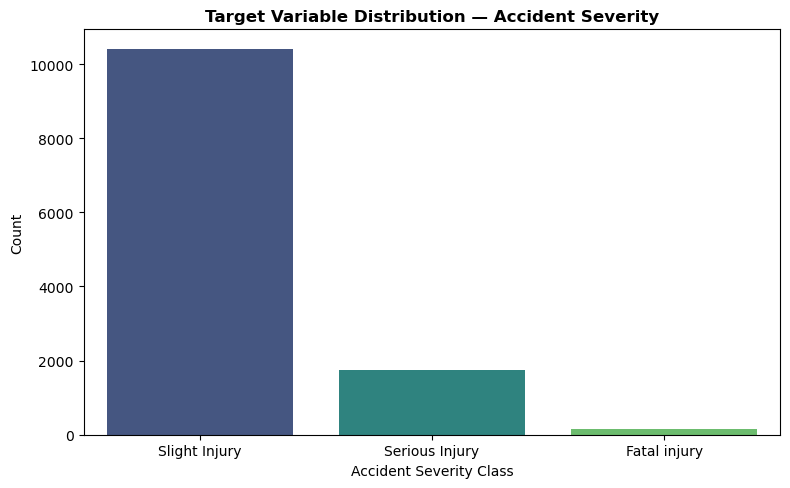

In [2]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Accident_severity', palette='viridis')
plt.title('Target Variable Distribution — Accident Severity', fontweight='bold', fontsize=12)
plt.xlabel('Accident Severity Class')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


In [3]:
# Clean and Encode Features
df_clean = df.copy()
for col in df_clean.columns:
    if df_clean[col].dtype == 'object':
        df_clean[col] = df_clean[col].fillna('Unknown')

df_clean['Hour'] = pd.to_datetime(df_clean['Time'], format='%H:%M:%S', errors='coerce').dt.hour.fillna(12).astype(int)

feature_cols = [c for c in df_clean.columns if c not in ['Time', 'Accident_severity']]
for col in feature_cols:
    if df_clean[col].dtype == 'object':
        df_clean[col] = LabelEncoder().fit_transform(df_clean[col].astype(str))

target_le = LabelEncoder()
df_clean['Target'] = target_le.fit_transform(df_clean['Accident_severity'])

X = df_clean[feature_cols]
y = df_clean['Target']

# Stratified 80:20 Split with random_state=42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")
print("Stratified Train-Test split and StandardScaler completed successfully (Zero Data Leakage).")


X_train shape: (9852, 31) | X_test shape: (2464, 31)
Stratified Train-Test split and StandardScaler completed successfully (Zero Data Leakage).


# 23CSE301 ML Capstone — Classification Notebook 06: Consolidated Part A Comparison
**Objective:** Summarize and compare all 5 Part-A classification algorithms (Logistic Regression, KNN, Gaussian Naive Bayes, Decision Tree, Support Vector Machine) on the RTA Dataset.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

results_data = [{'Algorithm': '1. Logistic Regression', 'Accuracy': 0.8454, 'Precision (weighted)': 0.7153, 'Recall (weighted)': 0.8454, 'F1-Score (weighted)': 0.7749, 'ROC-AUC (OvR)': np.float64(0.5802), 'Fit Time (s)': 0.043}, {'Algorithm': '2. K-Nearest Neighbors Classifier', 'Accuracy': 0.8377, 'Precision (weighted)': 0.7431, 'Recall (weighted)': 0.8377, 'F1-Score (weighted)': 0.7753, 'ROC-AUC (OvR)': np.float64(0.5615), 'Fit Time (s)': 0.001}, {'Algorithm': '3. Gaussian Naive Bayes', 'Accuracy': 0.8141, 'Precision (weighted)': 0.7323, 'Recall (weighted)': 0.8141, 'F1-Score (weighted)': 0.7648, 'ROC-AUC (OvR)': np.float64(0.5648), 'Fit Time (s)': 0.002}, {'Algorithm': '4. Decision Tree Classifier', 'Accuracy': 0.8413, 'Precision (weighted)': 0.7877, 'Recall (weighted)': 0.8413, 'F1-Score (weighted)': 0.7927, 'ROC-AUC (OvR)': np.float64(0.6119), 'Fit Time (s)': 0.039}, {'Algorithm': '5. Support Vector Machine (SVC)', 'Accuracy': 0.8458, 'Precision (weighted)': 0.7153, 'Recall (weighted)': 0.8458, 'F1-Score (weighted)': 0.7751, 'ROC-AUC (OvR)': np.float64(0.5747), 'Fit Time (s)': 15.666}]
summary_df = pd.DataFrame(results_data).sort_values(by='F1-Score (weighted)', ascending=False).reset_index(drop=True)
summary_df['Rank'] = range(1, len(summary_df) + 1)
summary_df = summary_df[['Rank', 'Algorithm', 'Accuracy', 'Precision (weighted)', 'Recall (weighted)', 'F1-Score (weighted)', 'ROC-AUC (OvR)', 'Fit Time (s)']]

print("="*85)
print("CONSOLIDATED CLASSIFICATION PART A COMPARISON TABLE (RTA DATASET)")
print("="*85)
summary_df


CONSOLIDATED CLASSIFICATION PART A COMPARISON TABLE (RTA DATASET)
 Rank                         Algorithm  Accuracy  Precision (weighted)  Recall (weighted)  F1-Score (weighted)  ROC-AUC (OvR)  Fit Time (s)
    1       4. Decision Tree Classifier    0.8413                0.7877             0.8413               0.7927         0.6119         0.039
    2 2. K-Nearest Neighbors Classifier    0.8377                0.7431             0.8377               0.7753         0.5615         0.001
    3   5. Support Vector Machine (SVC)    0.8458                0.7153             0.8458               0.7751         0.5747        15.666
    4            1. Logistic Regression    0.8454                0.7153             0.8454               0.7749         0.5802         0.043
    5           3. Gaussian Naive Bayes    0.8141                0.7323             0.8141               0.7648         0.5648         0.002


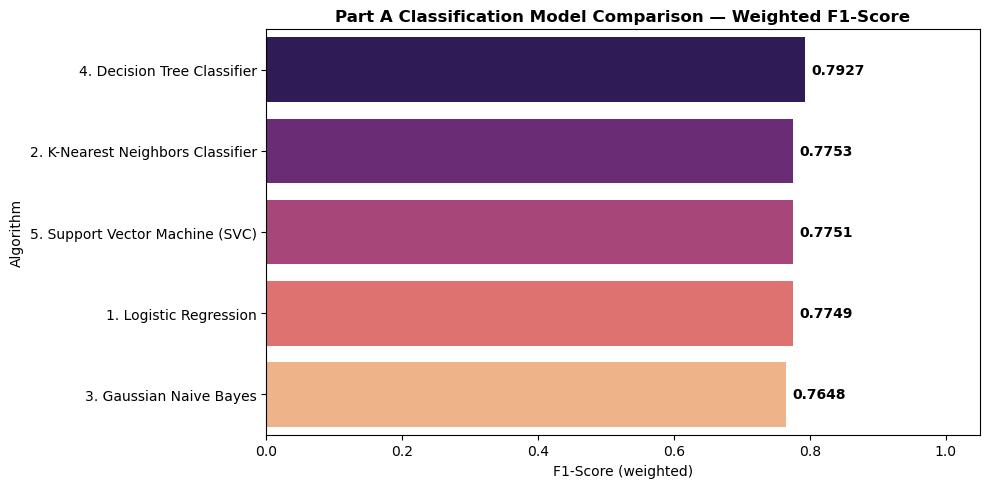

In [2]:
plt.figure(figsize=(10, 5))
sns.barplot(data=summary_df, x='F1-Score (weighted)', y='Algorithm', palette='magma')
plt.title('Part A Classification Model Comparison — Weighted F1-Score', fontsize=12, fontweight='bold')
plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()
